In [14]:
import pandas as pd

df = pd.read_csv(
    "sms+spam+collection/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())
print("Dataset shape:", df.shape)
print(df.isnull().sum())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dataset shape: (5572, 2)
label      0
message    0
dtype: int64


In [15]:
print(df["label"].value_counts())

print("\nPercentage:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

label
ham     4825
spam     747
Name: count, dtype: int64

Percentage:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [16]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["clean_message"] = df["message"].apply(clean_text)

print(df[["message", "clean_message"]].head())

                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                       clean_message  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4        nah dont think goes usf lives around though  

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vijay\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=3000)

X = tfidf.fit_transform(df["clean_message"])
y = df["label"].map({"ham": 0, "spam": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("First 10 feature names:")
print(tfidf.get_feature_names_out()[:10])

Feature shape: (5572, 3000)
Target shape: (5572,)
First 10 feature names:
['aah' 'aathilove' 'aathiwhere' 'abi' 'abiola' 'able' 'abt' 'abta' 'ac'
 'acc']


TF-IDF

TF-IDF stands for Term Frequency–Inverse Document Frequency. It converts text into numerical features for machine learning.

- Term Frequency (TF): How often a word appears in a message.
- Inverse Document Frequency (IDF): Gives less weight to words that appear in many messages and more weight to words that are more useful for distinguishing messages.

TF-IDF helps the model identify words that may be useful for classifying spam and normal messages.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (4457, 3000)
Testing data: (1115, 3000)
Training labels: (4457,)
Testing labels: (1115,)


In [20]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

nb_predictions = nb_model.predict(X_test)

print("Naive Bayes model trained successfully!")
print("First 10 predictions:", nb_predictions[:10])
print("First 10 actual labels:", y_test.iloc[:10].values)

Naive Bayes model trained successfully!
First 10 predictions: [0 0 0 1 0 0 0 0 0 0]
First 10 actual labels: [0 0 0 1 0 0 0 0 0 0]


In [21]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")
print("First 10 predictions:", lr_predictions[:10])
print("First 10 actual labels:", y_test.iloc[:10].values)

Logistic Regression model trained successfully!
First 10 predictions: [0 0 0 1 0 0 0 0 0 0]
First 10 actual labels: [0 0 0 1 0 0 0 0 0 0]


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

models = {
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions
}

for name, predictions in models.items():
    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions), 4))
    print("Recall:", round(recall_score(y_test, predictions), 4))
    print("F1-score:", round(f1_score(y_test, predictions), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))


 Naive Bayes
Accuracy: 0.9731
Precision: 0.9917
Recall: 0.8054
F1-score: 0.8889
Confusion Matrix:
 [[965   1]
 [ 29 120]]

 Logistic Regression
Accuracy: 0.965
Precision: 1.0
Recall: 0.7383
F1-score: 0.8494
Confusion Matrix:
 [[966   0]
 [ 39 110]]


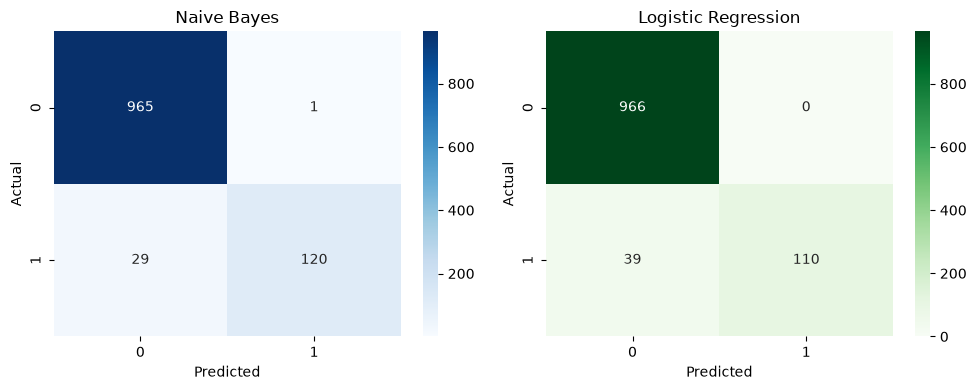

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

nb_cm = confusion_matrix(y_test, nb_predictions)
lr_cm = confusion_matrix(y_test, lr_predictions)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(nb_cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Naive Bayes")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(lr_cm, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Why is Recall Important in Spam Detection?

Recall is important in spam detection because it measures how many actual spam messages are correctly identified by the model.

If a spam message is classified as a normal message, it may reach the user's inbox. This can expose users to unwanted messages, scams, and phishing links.

In this project, Multinomial Naive Bayes achieved a recall of 80.54%, while Logistic Regression achieved 73.83%. Therefore, Naive Bayes identified a larger proportion of spam messages in the test dataset.

A higher recall helps reduce missed spam messages, although precision must also be considered to avoid incorrectly marking normal messages as spam.

 Conclusion

In this project, I built a spam detection model using Natural Language Processing and machine learning.

The SMS dataset was loaded and checked for missing values and class distribution. Text preprocessing was performed by converting messages to lowercase and removing punctuation and common stopwords. TF-IDF was used to convert text messages into numerical features.

Multinomial Naive Bayes and Logistic Regression models were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

On the test dataset, Naive Bayes achieved 97.31% accuracy and 80.54% recall. Logistic Regression achieved 96.50% accuracy and 73.83% recall. Naive Bayes performed better overall on this test, especially in identifying spam messages.

This project helped me understand text preprocessing, TF-IDF feature extraction, model training, and evaluation for spam classification.